# Wasserstein Autoencoder (WAE)

Balance reconstruction with maximum mean discrepancy between the aggregate encoded distribution and the prior. This notebook demonstrates the MMD form of WAE.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

Using device: cuda


## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 2. Wasserstein Autoencoder (WAE) with MMD

WAE minimizes reconstruction cost while matching the aggregate posterior `q(z)` to the prior. Here the discrepancy is maximum mean discrepancy (MMD) with a mixture of RBF kernels. This differs from the VAE's per-example KL regularization. AAE can also use adversarial aggregate matching; WAE describes a broader objective and matching choices.

In [2]:
def mmd_rbf(x, y, scales=(0.5, 1.0, 2.0, 4.0)):
    # Biased MMD estimate with a multi-scale RBF kernel.
    xx = torch.cdist(x, x).square(); yy = torch.cdist(y, y).square(); xy = torch.cdist(x, y).square()
    k_xx = sum(torch.exp(-xx / (2 * s)) for s in scales) / len(scales)
    k_yy = sum(torch.exp(-yy / (2 * s)) for s in scales) / len(scales)
    k_xy = sum(torch.exp(-xy / (2 * s)) for s in scales) / len(scales)
    return k_xx.mean() + k_yy.mean() - 2 * k_xy.mean()

wae = MLPVAE().to(device); wae_optim = torch.optim.Adam(wae.parameters(), lr=1e-3)

def wae_train_step(x, mmd_weight=10.0):
    x = x.to(device); recon, mu, logvar = wae(x); z = wae.reparameterize(mu, logvar)
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    match = mmd_rbf(z, torch.randn_like(z)); loss = rec + mmd_weight * match
    wae_optim.zero_grad(); loss.backward(); wae_optim.step()
    return {'loss': loss.item(), 'reconstruction': rec.item(), 'mmd': match.item()}

# Example: metrics = wae_train_step(sample_batch(train_loader))

## Full training — 50 epochs

This runs on the full MNIST training split using the model-specific objective above. In Colab, select a GPU runtime for faster training. The final checkpoint includes model weights, optimizer state, and epoch metrics.

In [3]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = wae_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
    print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "model": wae.state_dict(),
    "optimizers": {"wae_optim": wae_optim.state_dict()},
    "epochs": epochs,
    "history": history
}
checkpoint_path = Path("10_WAE_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | loss=136.2163 | reconstruction=135.9490 | mmd=0.0267
Epoch 02/50 | loss=87.3819 | reconstruction=87.1185 | mmd=0.0263
Epoch 03/50 | loss=81.5471 | reconstruction=81.2836 | mmd=0.0263
Epoch 04/50 | loss=78.6912 | reconstruction=78.4281 | mmd=0.0263
Epoch 05/50 | loss=76.8495 | reconstruction=76.5860 | mmd=0.0264
Epoch 06/50 | loss=75.5193 | reconstruction=75.2553 | mmd=0.0264
Epoch 07/50 | loss=74.5018 | reconstruction=74.2394 | mmd=0.0262
Epoch 08/50 | loss=73.7039 | reconstruction=73.4408 | mmd=0.0263
Epoch 09/50 | loss=73.0394 | reconstruction=72.7764 | mmd=0.0263
Epoch 10/50 | loss=72.4488 | reconstruction=72.1854 | mmd=0.0263
Epoch 11/50 | loss=71.9889 | reconstruction=71.7254 | mmd=0.0264
Epoch 12/50 | loss=71.5788 | reconstruction=71.3156 | mmd=0.0263
Epoch 13/50 | loss=71.2254 | reconstruction=70.9619 | mmd=0.0263
Epoch 14/50 | loss=70.9119 | reconstruction=70.6491 | mmd=0.0263
Epoch 15/50 | loss=70.6132 | reconstruction=70.3490 | mmd=0.0264
Epoch 16/50 | loss=70.3

## Inspect reconstructions and prior samples

Use these plots alongside the objective metrics; no single number captures reconstruction quality, prior matching, latent use, and sample quality.

Aggregate posterior MMD estimate on this batch: 0.0277


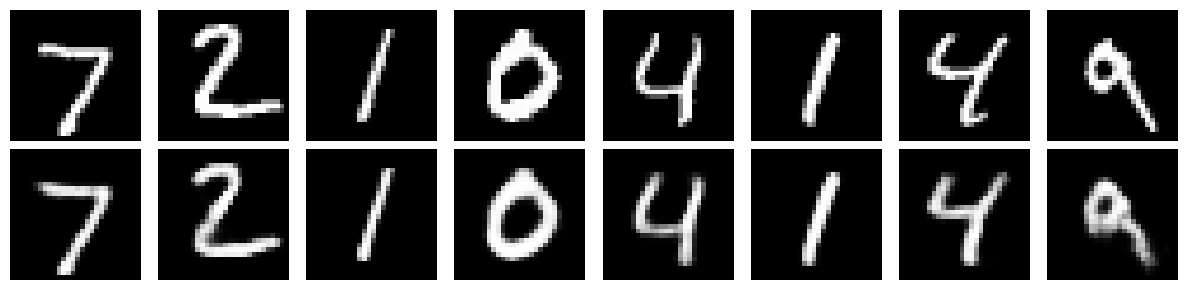

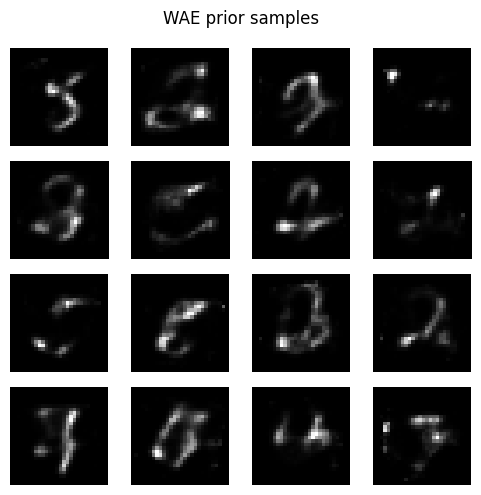

In [4]:
x = sample_batch(test_loader)[:8]
wae.eval()
with torch.no_grad():
    mu, logvar = wae.encode(x); recon = wae.decode(wae.reparameterize(mu, logvar))
    prior_samples = wae.decode(torch.randn(16, wae.latent_dim, device=device))
    z_aggregate = wae.reparameterize(*wae.encode(sample_batch(test_loader)))
    discrepancy = mmd_rbf(z_aggregate, torch.randn_like(z_aggregate)).item()
print(f'Aggregate posterior MMD estimate on this batch: {discrepancy:.4f}')
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap='gray'); ax.axis('off')
plt.suptitle('WAE prior samples'); plt.tight_layout(); plt.show()